In [2]:
import pandas as pd
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [3]:
df  = pd.read_csv("loan_approval_data.csv")

In [4]:
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    object 
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    object 
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    object 
 15  Property_Area       950 non-null    object 
 16  Educati

In [6]:
df.isnull().sum()

Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64

In [7]:
df.describe()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term
count,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000
mean,501.220000,10852.571579,5082.455789,39.971579,1.474737,676.033684,1.950526,0.347263,9940.452632,24802.792632,20522.825263,48.000000
std,289.608451,5061.632859,2943.161570,11.139797,1.105067,71.346015,1.406246,0.144341,5860.736885,14345.696031,11504.142575,24.245322
min,1.000000,2009.000000,1.000000,21.000000,0.000000,550.000000,0.000000,0.100000,65.000000,36.000000,1015.000000,12.000000
25%,250.250000,6730.750000,2472.750000,30.250000,1.000000,616.250000,1.000000,0.220000,4760.250000,12698.250000,9806.250000,24.000000
50%,499.500000,10548.000000,5205.500000,40.000000,1.000000,678.000000,2.000000,0.340000,9880.500000,24321.000000,21210.500000,48.000000
75%,752.750000,15190.000000,7620.750000,49.000000,2.000000,737.000000,3.000000,0.480000,15074.500000,36947.000000,30263.000000,72.000000
max,1000.000000,19988.000000,9996.000000,59.000000,3.000000,799.000000,4.000000,0.600000,19996.000000,49954.000000,39995.000000,84.000000


In [8]:
catogorical_col = df.select_dtypes(include=["object"]).columns # select only objects data inside the  columns 
print(catogorical_col)

Index(['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area',
       'Education_Level', 'Gender', 'Employer_Category', 'Loan_Approved'],
      dtype='object')


In [9]:
numerical_col = df.select_dtypes(include=["float64","int64"]).columns  # select only float,int numerrical format data inside the columns
print(numerical_col)

Index(['Applicant_ID', 'Applicant_Income', 'Coapplicant_Income', 'Age',
       'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings',
       'Collateral_Value', 'Loan_Amount', 'Loan_Term'],
      dtype='object')


In [10]:
from sklearn.impute import SimpleImputer # handel the missing value 
num_imp = SimpleImputer(strategy="mean") # replace withe mean 
df[numerical_col] =  num_imp.fit_transform(df[numerical_col])

In [11]:
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


In [12]:
cat_imp = SimpleImputer(strategy="most_frequent") # mode 
df[catogorical_col] = cat_imp.fit_transform(df[catogorical_col])

In [13]:
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


In [14]:
# to verfiy the miasing value 

df.isnull().sum()

Applicant_ID          0
Applicant_Income      0
Coapplicant_Income    0
Employment_Status     0
Age                   0
Marital_Status        0
Dependents            0
Credit_Score          0
Existing_Loans        0
DTI_Ratio             0
Savings               0
Collateral_Value      0
Loan_Amount           0
Loan_Term             0
Loan_Purpose          0
Property_Area         0
Education_Level       0
Gender                0
Employer_Category     0
Loan_Approved         0
dtype: int64

# EDA 




Text(0.5, 1.0, 'is loan approved or not')

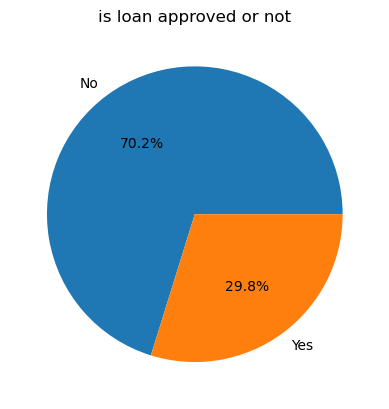

In [15]:
# how balance class are 


class_count = df["Loan_Approved"].value_counts()
plt.pie(class_count, labels=["No","Yes"] ,autopct="%1.1f%%")
plt.title("is loan approved or not")

<Axes: xlabel='Gender', ylabel='count'>

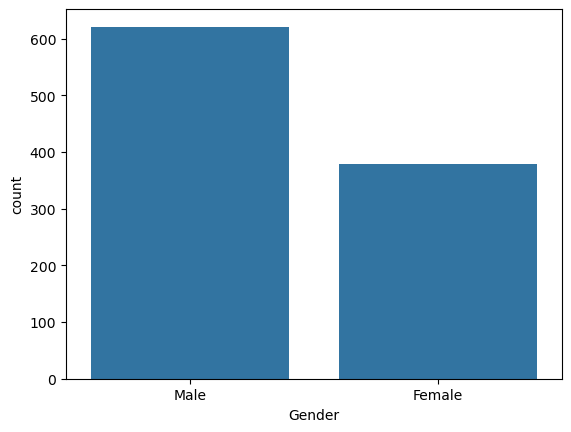

In [16]:
# gender categories 

gender_count = df["Gender"].value_counts()
sns.barplot(gender_count)


<Axes: xlabel='Education_Level', ylabel='count'>

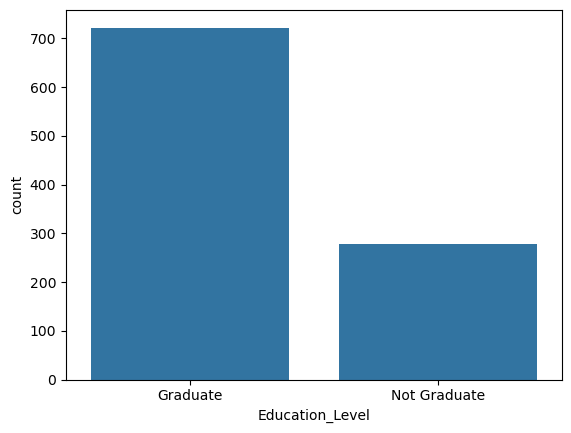

In [17]:
#Education_Level

edu_count = df["Education_Level"].value_counts()
sns.barplot(edu_count)


<Axes: xlabel='count', ylabel='Count'>

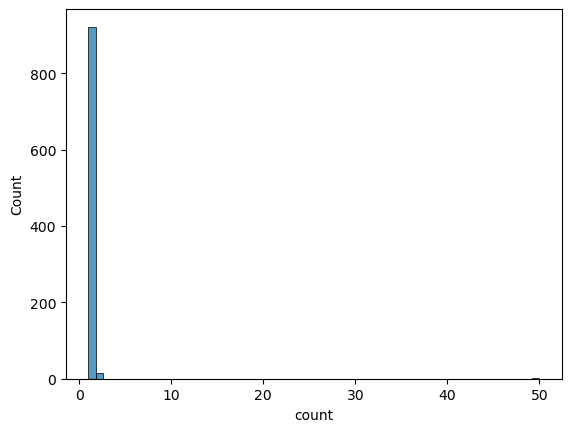

In [18]:
#Loan_Amount 
loan_an_count = df["Loan_Amount"].value_counts()
sns.histplot(loan_an_count)



<Axes: xlabel='Applicant_Income', ylabel='Count'>

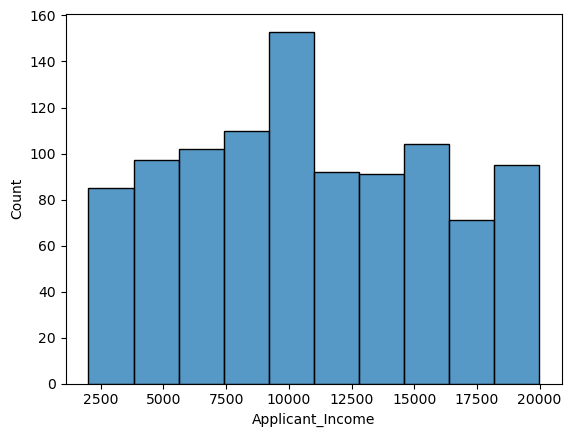

In [19]:
# anaylze income 

sns.histplot(
    data=df,
    x = "Applicant_Income",
    bins = 10
)

<Axes: xlabel='Coapplicant_Income', ylabel='Count'>

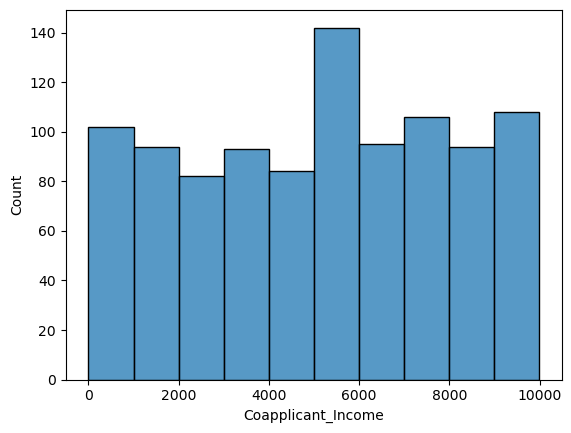

In [20]:
sns.histplot(
    data=df,
    x = "Coapplicant_Income",
    bins = 10
)

<Axes: xlabel='Loan_Approved', ylabel='Applicant_Income'>

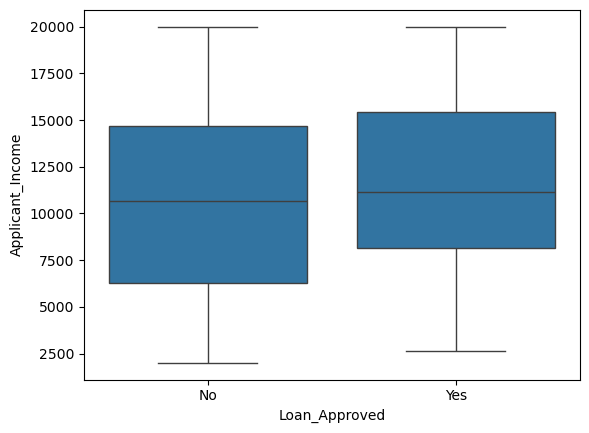

In [21]:
# outliers detection for box plot 

sns.boxplot(

    data=df,
    x="Loan_Approved",
    y="Applicant_Income"
)

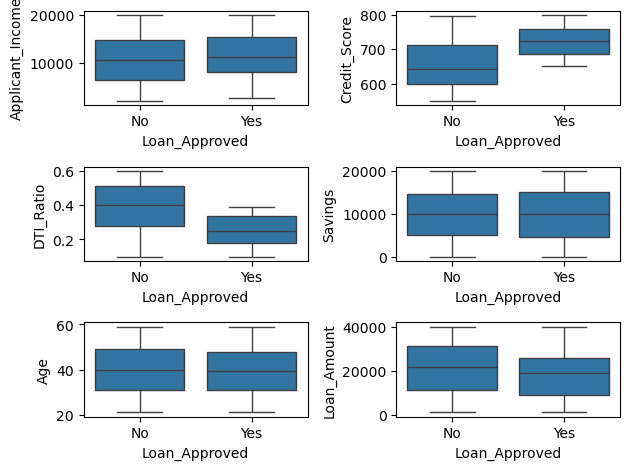

In [22]:
# multi box plot for detection outliers 

fig,axes = plt.subplots(3,2)
sns.boxplot(ax = axes[0, 0],data=df,x="Loan_Approved", y="Applicant_Income")
sns.boxplot(ax = axes[0, 1],data=df,x="Loan_Approved", y="Credit_Score")
sns.boxplot(ax = axes[1, 0],data=df,x="Loan_Approved", y="DTI_Ratio")
sns.boxplot(ax = axes[1, 1],data=df,x="Loan_Approved", y="Savings")
sns.boxplot(ax = axes[2, 0],data=df,x="Loan_Approved", y="Age")
sns.boxplot(ax = axes[2, 1],data=df,x="Loan_Approved", y="Loan_Amount")


plt.tight_layout()


<Axes: xlabel='Credit_Score', ylabel='Count'>

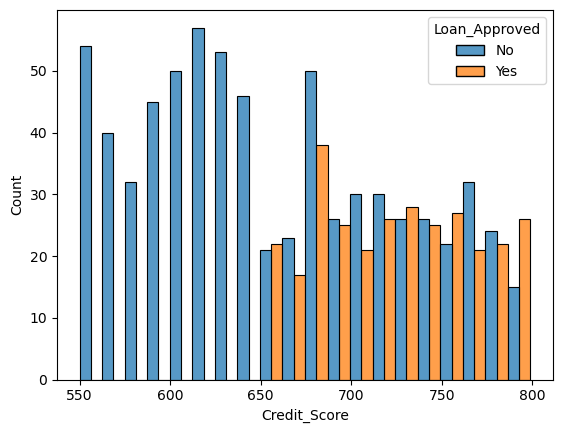

In [23]:
# create score with loan approved 

sns.histplot(
    data=df,
    x="Credit_Score",
    hue="Loan_Approved",
    bins = 20,
    multiple = "dodge"
)

In [24]:
# remove applicant_id 

# un nessaary feature

df = df.drop("Applicant_ID", axis = 1)



In [25]:
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


In [26]:
# feature encoding 

In [27]:
from sklearn.preprocessing import LabelEncoder ,OneHotEncoder

le = LabelEncoder()
df["Education_Level"] = le.fit_transform(df["Education_Level"])
df["Loan_Approved"] = le.fit_transform(df["Loan_Approved"])


# ONE hot encoder 
cols = ["Employment_Status","Loan_Purpose", "Marital_Status","Property_Area","Employer_Category","Gender"]
ohe = OneHotEncoder(drop="first",sparse_output=False,handle_unknown="ignore") 
encoder = ohe.fit_transform(df[cols]) # its give a array values 

encoder_df = pd.DataFrame(encoder,columns=ohe.get_feature_names_out(cols),index=df.index)

df = pd.concat([df.drop(columns= cols),encoder_df],axis=1) # drop the old columns and add new encoder value and columns in ols data set 

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 28 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Applicant_Income                 1000 non-null   float64
 1   Coapplicant_Income               1000 non-null   float64
 2   Age                              1000 non-null   float64
 3   Dependents                       1000 non-null   float64
 4   Credit_Score                     1000 non-null   float64
 5   Existing_Loans                   1000 non-null   float64
 6   DTI_Ratio                        1000 non-null   float64
 7   Savings                          1000 non-null   float64
 8   Collateral_Value                 1000 non-null   float64
 9   Loan_Amount                      1000 non-null   float64
 10  Loan_Term                        1000 non-null   float64
 11  Education_Level                  1000 non-null   int64  
 12  Loan_Approved        

# correlation heatmap


lies btween -1 to 1


In [29]:
# realtion ship between each columns with every columns 


num_cols  = df.select_dtypes(include="number")
corr_matrix = num_cols.corr()

In [30]:
corr_matrix

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Loan_Purpose_Home,Loan_Purpose_Personal,Marital_Status_Single,Property_Area_Semiurban,Property_Area_Urban,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed,Gender_Male
Applicant_Income,1.000000,0.007545,-0.023988,-0.026658,-0.009818,-0.010457,-0.009107,-0.028358,0.018789,-0.024143,...,0.074209,-0.031234,0.010057,0.004845,-0.036260,-0.025011,0.102589,-0.044639,-0.011995,-0.020871
Coapplicant_Income,0.007545,1.000000,0.014306,-0.026733,0.058423,0.012418,0.058078,-0.015047,0.009457,0.001596,...,0.016022,0.059549,-0.011431,-0.010058,0.030045,-0.001146,0.037640,0.004312,-0.047929,-0.010148
Age,-0.023988,0.014306,1.000000,-0.018767,-0.004212,0.023330,0.007903,-0.000986,0.037382,0.013502,...,0.029865,0.037293,0.009162,0.003100,-0.025661,-0.066041,0.021232,-0.012960,0.072462,0.048402
Dependents,-0.026658,-0.026733,-0.018767,1.000000,-0.007687,-0.026338,0.011498,-0.004981,0.023004,-0.017409,...,0.027343,-0.005785,-0.011410,-0.032278,0.024082,-0.009250,-0.018757,0.030197,-0.054147,0.013706
Credit_Score,-0.009818,0.058423,-0.004212,-0.007687,1.000000,-0.007130,0.002338,-0.065353,0.007865,0.001002,...,-0.008658,0.015324,0.056176,-0.006946,0.004445,-0.007076,0.066736,-0.000049,-0.046087,-0.039739
Existing_Loans,-0.010457,0.012418,0.023330,-0.026338,-0.007130,1.000000,0.047008,0.034435,-0.049916,-0.021035,...,0.001777,0.023212,0.018010,-0.053971,0.035629,-0.009642,0.030520,-0.019306,0.045391,-0.038762
DTI_Ratio,-0.009107,0.058078,0.007903,0.011498,0.002338,0.047008,1.000000,0.004663,-0.009622,0.075784,...,-0.014125,-0.036648,-0.014850,0.044898,-0.006156,-0.007214,0.002090,-0.003506,0.026018,0.009624
Savings,-0.028358,-0.015047,-0.000986,-0.004981,-0.065353,0.034435,0.004663,1.000000,0.015481,-0.012208,...,-0.012217,-0.028948,-0.004131,0.005438,0.016833,-0.011683,0.004381,-0.030208,0.027178,-0.006667
Collateral_Value,0.018789,0.009457,0.037382,0.023004,0.007865,-0.049916,-0.009622,0.015481,1.000000,0.002660,...,-0.050975,-0.007120,0.018450,0.020061,0.007975,0.035760,-0.013464,-0.014480,-0.009655,0.000897
Loan_Amount,-0.024143,0.001596,0.013502,-0.017409,0.001002,-0.021035,0.075784,-0.012208,0.002660,1.000000,...,-0.000930,0.032498,0.004683,0.040206,-0.050076,0.013108,-0.025975,0.013923,-0.026566,0.103456


In [31]:
# realtionship between all columns with output(loan approved) columns 

num_cols.corr()["Loan_Approved"].sort_values(ascending=False)

Loan_Approved                      1.000000
Credit_Score                       0.451175
Applicant_Income                   0.119796
Employer_Category_MNC              0.069049
Loan_Purpose_Personal              0.034043
Marital_Status_Single              0.030182
Property_Area_Urban                0.025963
Collateral_Value                   0.021868
Coapplicant_Income                 0.004230
Loan_Purpose_Home                  0.002118
Employment_Status_Self-employed   -0.001337
Employer_Category_Private         -0.003347
Property_Area_Semiurban           -0.012967
Savings                           -0.013437
Loan_Purpose_Education            -0.016684
Employer_Category_Unemployed      -0.021468
Age                               -0.022343
Dependents                        -0.023811
Existing_Loans                    -0.034794
Employer_Category_Government      -0.039187
Employment_Status_Salaried        -0.041428
Employment_Status_Unemployed      -0.044464
Education_Level                 

<Axes: >

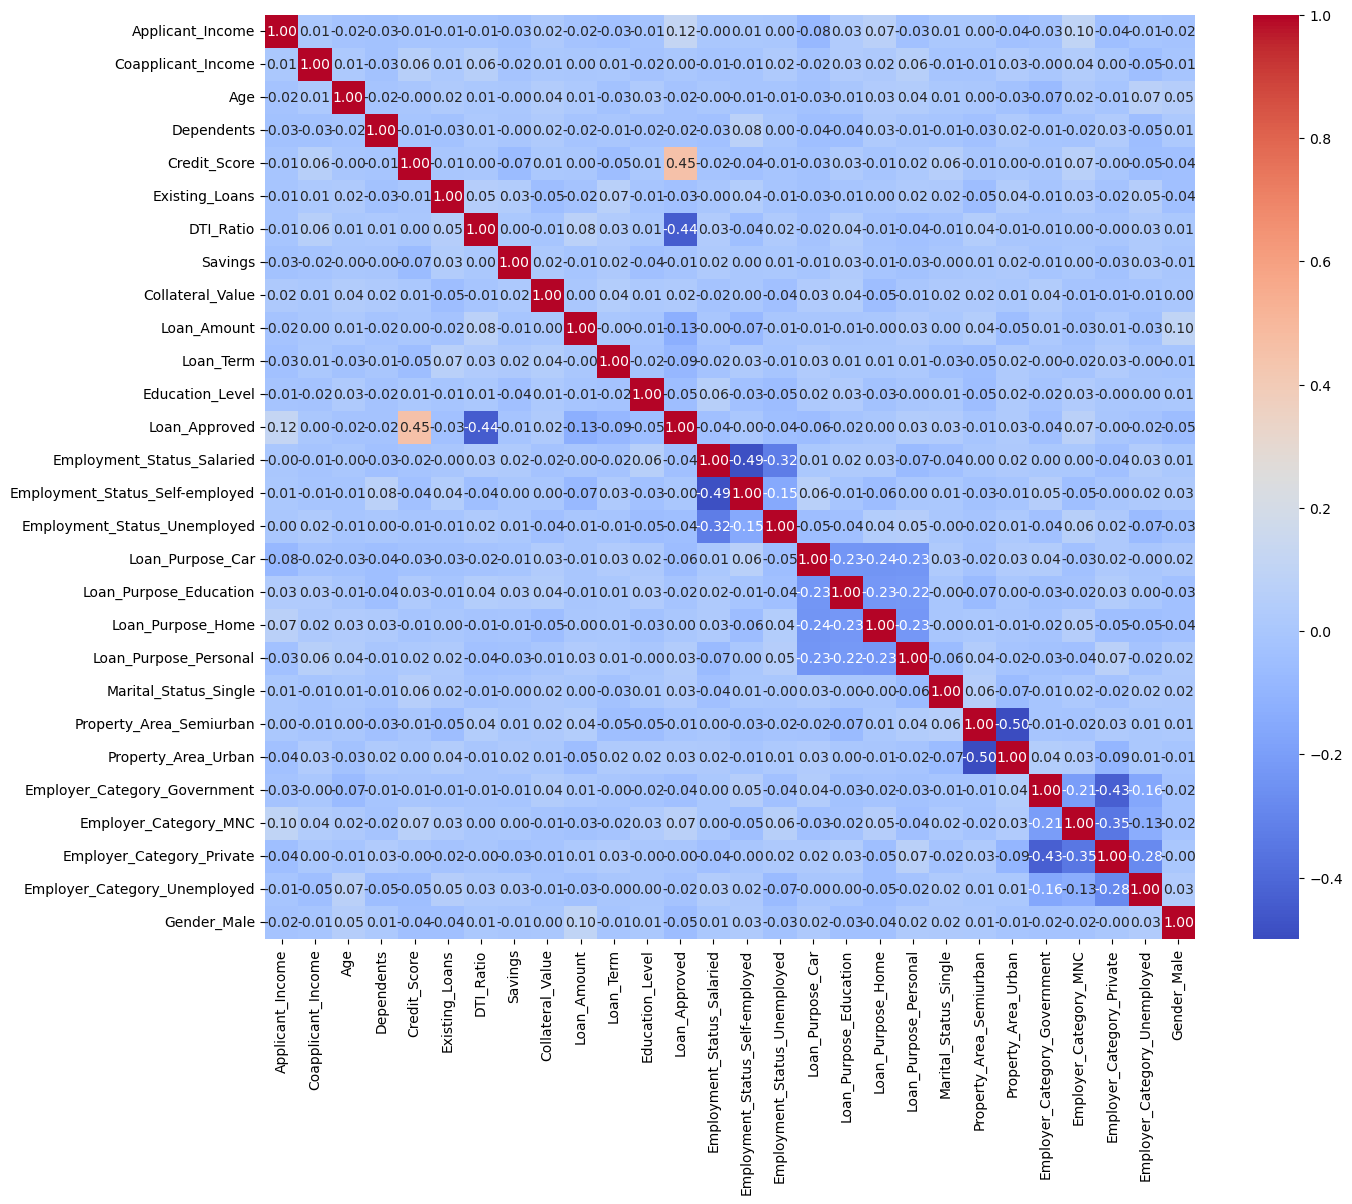

In [32]:
num_cols  = df.select_dtypes(include="number")
corr_matrix = num_cols.corr()
plt.figure(figsize=(15,12))
sns.heatmap(

    corr_matrix,
    annot=True,
    fmt=".2f",# values in 2 deciaml
    cmap="coolwarm"
    
)

# train_test _split

In [33]:
X = df.drop("Loan_Approved",axis =1)
y = df["Loan_Approved"]

In [34]:
X_train,X_test,y_train,y_test = train_test_split(

    X,y,test_size=0.2,random_state=42
)

In [35]:
X_train.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Loan_Purpose_Home,Loan_Purpose_Personal,Marital_Status_Single,Property_Area_Semiurban,Property_Area_Urban,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed,Gender_Male
29,5890.000000,8041.0,31.000000,0.0,603.000000,0.000000,0.11,11906.0,8150.000000,29287.000000,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
535,4779.000000,529.0,50.000000,0.0,614.000000,0.000000,0.21,5369.0,5430.000000,14786.000000,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
695,10852.571579,8927.0,36.000000,0.0,584.000000,4.000000,0.22,3186.0,24802.792632,20522.825263,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
557,2384.000000,2113.0,39.971579,1.0,726.000000,4.000000,0.34,11882.0,48542.000000,13312.000000,...,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
836,5228.000000,5249.0,42.000000,1.0,676.033684,1.950526,0.18,17669.0,24802.792632,13906.000000,...,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


In [36]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaler = scaler.fit_transform(X_train)
X_test_scaler = scaler.transform(X_test)

TRAIN AND EVULATE MODEL

# logestic reegresssion

In [37]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression()
log_model.fit(X_train_scaler, y_train)



,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [38]:
y_pred = log_model.predict(X_test_scaler)

# high risky customer get apporved it is true negtive condition that is approved is postive and high riskey customerr is negtive for this use a percision score



In [39]:
from sklearn.metrics import accuracy_score, precision_score,recall_score,f1_score , confusion_matrix
print("logistic_regression")
print("precision_score",precision_score(y_test,y_pred)) 
print("recall_score",recall_score(y_test,y_pred))
print("accuracy_score",accuracy_score(y_test,y_pred)) 
print("confusion_matrix",confusion_matrix(y_test,y_pred)) 

logistic_regression
precision_score 0.7833333333333333
recall_score 0.7704918032786885
accuracy_score 0.865
confusion_matrix [[126  13]
 [ 14  47]]


# navie bayes 


In [40]:
from sklearn.naive_bayes import GaussianNB

nav = GaussianNB()
nav.fit(X_train_scaler,y_train)

,priors,None
,var_smoothing,1e-09


In [41]:
y_pred = nav.predict(X_test_scaler)

In [42]:
print("Navie_bayes")
print("precision_score",precision_score(y_test,y_pred)) 
print("recall_score",recall_score(y_test,y_pred))
print("accuracy_score",accuracy_score(y_test,y_pred)) 
print("confusion_matrix",confusion_matrix(y_test,y_pred)) 

Navie_bayes
precision_score 0.8035714285714286
recall_score 0.7377049180327869
accuracy_score 0.865
confusion_matrix [[128  11]
 [ 16  45]]



#KNN


In [43]:
from sklearn.neighbors import KNeighborsClassifier 

knn = KNeighborsClassifier()
knn.fit(X_train_scaler,y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [44]:
y_pred = knn.predict(X_test_scaler)

In [45]:
print("KNN")
print("precision_score",precision_score(y_test,y_pred)) 
print("recall_score",recall_score(y_test,y_pred))
print("accuracy_score",accuracy_score(y_test,y_pred)) 
print("confusion_matrix",confusion_matrix(y_test,y_pred)) 

KNN
precision_score 0.6274509803921569
recall_score 0.5245901639344263
accuracy_score 0.76
confusion_matrix [[120  19]
 [ 29  32]]


# best model is navie bayes model 


In [46]:
# feature engineering for impove model 

In [ ]:
# add and transform a data 

In [54]:
df["DTI_Ratio_sq"] = df["DTI_Ratio"]  **2 # higy negtive value accordding to heat map so impaact in data 
df["Credit_Score_sq"] = df["Credit_Score"]  **2 # higy posstive value accordding to heat map so impaact in data 

df["Applicant_Income_log"] = np.log1p(df["Applicant_Income"]) # only for skwed data 



X = df.drop(columns = ["Loan_Approved", "DTI_Ratio","Credit_Score"])
y = df["Loan_Approved"]


X_train,X_test,y_train,y_test = train_test_split(

    X,y,test_size=0.2,random_state=42
)

scaler = StandardScaler()

X_train_scaler = scaler.fit_transform(X_train)
X_test_scaler = scaler.transform(X_test)

In [55]:
X_train.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Existing_Loans,Savings,Collateral_Value,Loan_Amount,Loan_Term,Education_Level,...,Property_Area_Semiurban,Property_Area_Urban,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed,Gender_Male,DTI_Ratio_sq,Credit_Score_sq,Applicant_Income_log
29,5890.000000,8041.0,31.000000,0.0,0.000000,11906.0,8150.000000,29287.000000,12.0,1,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0121,363609.000000,8.681181
535,4779.000000,529.0,50.000000,0.0,0.000000,5369.0,5430.000000,14786.000000,72.0,1,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0441,376996.000000,8.472196
695,10852.571579,8927.0,36.000000,0.0,4.000000,3186.0,24802.792632,20522.825263,48.0,1,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0484,341056.000000,9.292249
557,2384.000000,2113.0,39.971579,1.0,4.000000,11882.0,48542.000000,13312.000000,24.0,0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.1156,527076.000000,7.776954
836,5228.000000,5249.0,42.000000,1.0,1.950526,17669.0,24802.792632,13906.000000,84.0,0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0324,457021.542187,8.561975


In [56]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression()
log_model.fit(X_train_scaler, y_train)
y_pred = log_model.predict(X_test_scaler)

from sklearn.metrics import accuracy_score, precision_score,recall_score,f1_score , confusion_matrix
print("logistic_regression")
print("precision_score",precision_score(y_test,y_pred)) 
print("recall_score",recall_score(y_test,y_pred))
print("accuracy_score",accuracy_score(y_test,y_pred)) 
print("confusion_matrix",confusion_matrix(y_test,y_pred)) 

logistic_regression
precision_score 0.7846153846153846
recall_score 0.8360655737704918
accuracy_score 0.88
confusion_matrix [[125  14]
 [ 10  51]]


In [62]:
from sklearn.naive_bayes import GaussianNB

nav = GaussianNB()
nav.fit(X_train_scaler,y_train)
y_pred = nav.predict(X_test_scaler)
print("Navie_bayes")
print("precision_score",precision_score(y_test,y_pred)) 
print("recall_score",recall_score(y_test,y_pred))
print("accuracy_score",accuracy_score(y_test,y_pred)) 
print("confusion_matrix",confusion_matrix(y_test,y_pred)) 

Navie_bayes
precision_score 0.8113207547169812
recall_score 0.7049180327868853
accuracy_score 0.86
confusion_matrix [[129  10]
 [ 18  43]]


In [58]:
from sklearn.neighbors import KNeighborsClassifier 

knn = KNeighborsClassifier()
knn.fit(X_train_scaler,y_train)
y_pred = knn.predict(X_test_scaler)
print("KNN")
print("precision_score",precision_score(y_test,y_pred)) 
print("recall_score",recall_score(y_test,y_pred))
print("accuracy_score",accuracy_score(y_test,y_pred)) 
print("confusion_matrix",confusion_matrix(y_test,y_pred)) 

KNN
precision_score 0.6730769230769231
recall_score 0.5737704918032787
accuracy_score 0.785
confusion_matrix [[122  17]
 [ 26  35]]
